In [179]:
import pandas as pd
import numpy as np
import scipy
import seaborn as sns
import matplotlib.pyplot as plt
import os
from collections import Counter

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
input = "Genome_CleanInds_haploid"
os.system("plink --vcf " + input + ".vcf --make-rel square --out " + input)

In [237]:
relAll = pd.read_table("/sietch_colab/jobste/Data/Remapped/LowRecRegionsRemoved/SingerIndividuals/Genome_CleanInds_haploid.rel", header=None)
relAllID = pd.read_table("/sietch_colab/jobste/Data/Remapped/LowRecRegionsRemoved/SingerIndividuals/Genome_CleanInds_haploid.rel.id", header=None)
relAllIndex = relAll.index.values

In [239]:
meta = pd.read_csv("/sietch_colab/jobste/Data/TsinferMetaData_Vcf_Country.txt")
metaCleanInds = meta[meta.ID.isin(relAllID[0])]

In [240]:
print(meta.shape)
print(metaCleanInds.shape)

(1328, 5)
(462, 5)


In [241]:
offs = [num for num,value in zip(relAll.index, [max(x) for x in relAll.values]) if value > 20]
offIDs = [name for name,value in zip(relAllID[0], [max(x) for x in relAll.values]) if value > 20]
# These are the three scutellatas and the three capensis drones

In [242]:
meta.SubPop[meta.ID.isin(offIDs)]

185    Scutellata
197    Scutellata
203    Scutellata
216      Capensis
225      Capensis
289      Capensis
Name: SubPop, dtype: object

In [243]:
rel = relAll.drop(columns = offs)
rel = relAll.drop(offs)

In [138]:
relLog = np.log(rel)

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


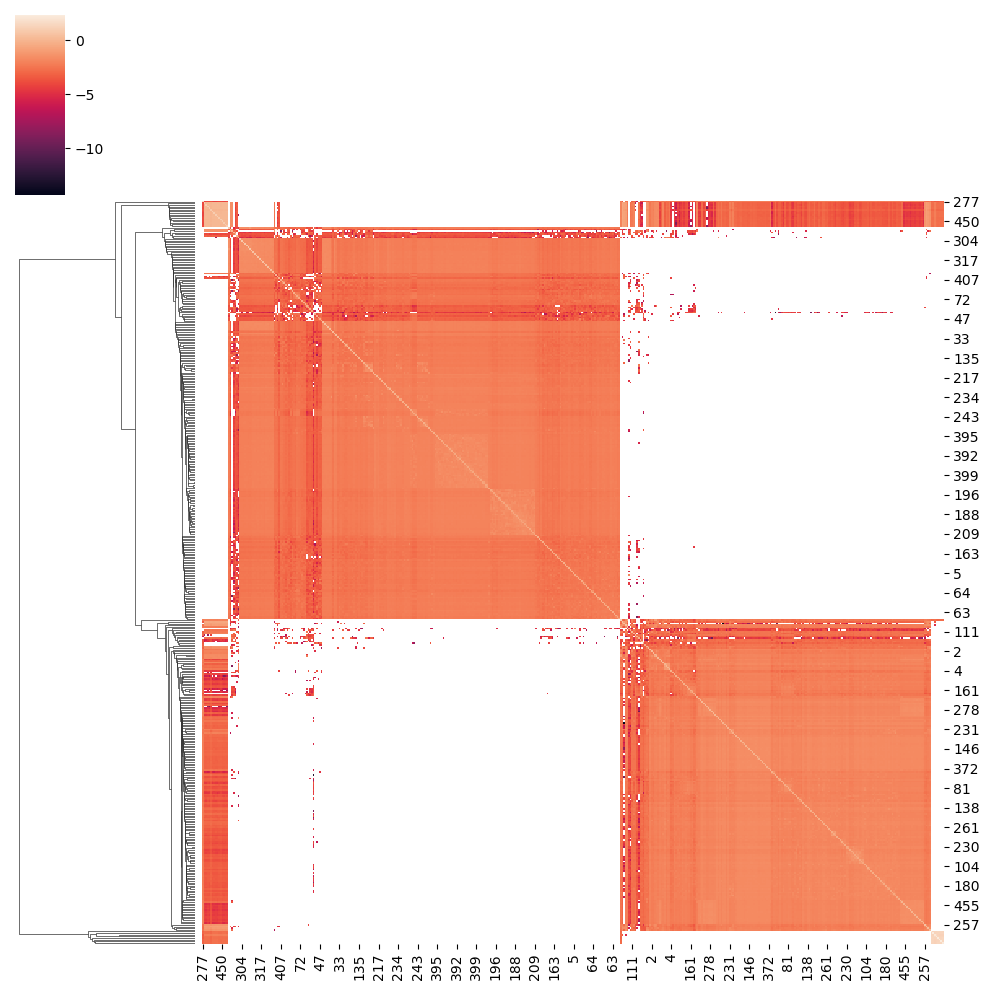

In [140]:
row_linkage = scipy.cluster.hierarchy.linkage(rel, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
#orderNames = [relID[[0]][x] for x in list(order)]
x_pop = [int(x) for x in rel.index.values[order]]
clustermap = sns.clustermap(relLog[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
#clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

In [180]:
# C lineage
C_ids = list(meta.ID[meta.Pop == "C"])
C_index = [index for index,name in zip(relIndex, relID[0]) if name in C_ids]
C_matrix = rel.loc[C_index, C_index]
C_matrixLog = np.log10(C_matrix)
row_linkage = scipy.cluster.hierarchy.linkage(C_matrix, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
#orderNames = [relID[[0]][x] for x in list(order)]
x_pop = [int(x) for x in C_matrix.index.values[order]]
clustermap = sns.clustermap(C_matrixLog[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
#clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


In [188]:
#Two cluster
max_d = 2 # example distance threshold
clusters = scipy.cluster.hierarchy.fcluster(row_linkage, max_d, criterion='distance')
print(len(set(clusters)))
from collections import Counter
Counter(clusters)

8


Counter({3: 174, 4: 1, 6: 1, 1: 1, 2: 1, 7: 1, 5: 1, 8: 1})

In [192]:
keep = [ind for ind,cluster in zip(C_matrix.index.values, clusters) if cluster == 3]
keepNames = relID[0][keep]
Counter(meta.SubPop[meta.ID.isin(keepNames)])

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


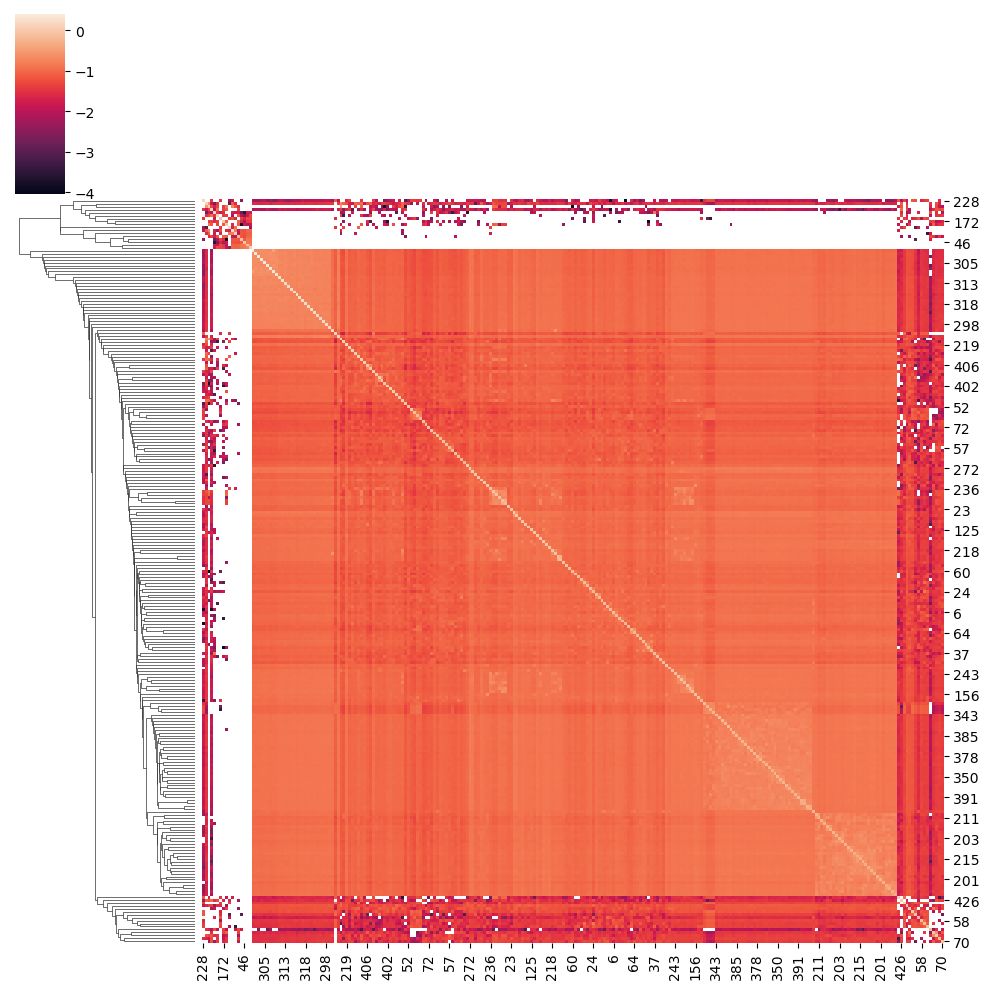

In [195]:
# M lineage
M_ids = list(meta.ID[meta.Pop == "M"])
M_index = [index for index,name in zip(relIndex, relID[0]) if name in M_ids]
M_matrix = rel.loc[M_index, M_index]
M_matrixLog = np.log10(M_matrix)

row_linkage = scipy.cluster.hierarchy.linkage(M_matrix, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
#orderNames = [relID[[0]][x] for x in list(order)]
x_pop = [int(x) for x in M_matrix.index.values[order]]
clustermap = sns.clustermap(M_matrixLog[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
#clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

In [201]:
#Three cluster
max_d = 2.5 # example distance threshold
clusters = scipy.cluster.hierarchy.fcluster(row_linkage, max_d, criterion='distance')
print(len(set(clusters)))
from collections import Counter
Counter(clusters)

3


Counter({2: 235, 1: 17, 3: 1})

In [205]:
keep = [ind for ind,cluster in zip(M_matrix.index.values, clusters) if cluster == 2]
keepNames = relID[0][keep]
Counter(meta.SubPop[meta.ID.isin(keepNames)])

Counter({'Mellifera': 210, 'Iberiensis': 25})

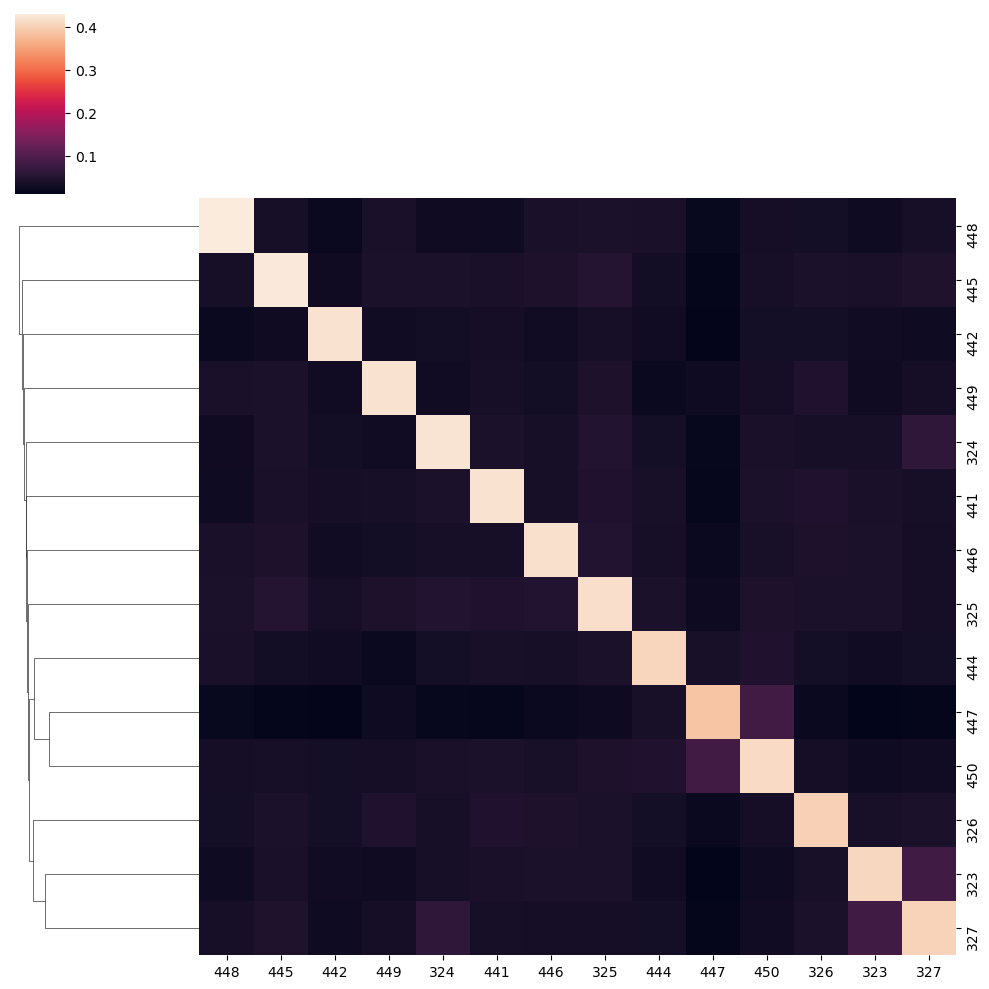

In [206]:
# O lineage
O_ids = list(meta.ID[meta.Pop == "O"])
O_index = [index for index,name in zip(relIndex, relID[0]) if name in O_ids]
O_matrix = rel.loc[O_index, O_index]
O_matrixLog = np.log10(O_matrix)

row_linkage = scipy.cluster.hierarchy.linkage(O_matrix, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
#orderNames = [relID[[0]][x] for x in list(order)]
x_pop = [int(x) for x in O_matrix.index.values[order]]
clustermap = sns.clustermap(O_matrixLog[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
#clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


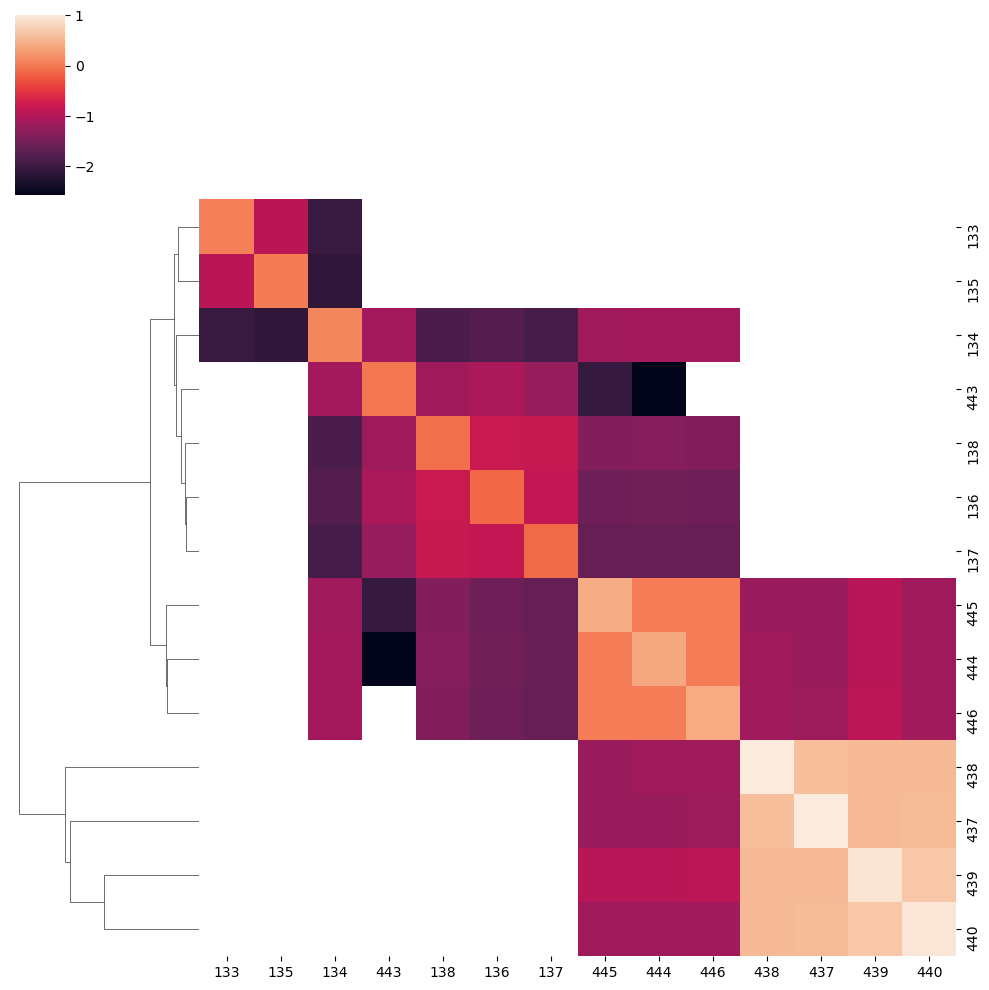

In [211]:
# A lineage
A_ids = list(meta.ID[meta.Pop == "A"])
A_index = [index for index,name in zip(relIndex, relID[0]) if name in A_ids]
A_matrix = rel.iloc[A_index, A_index]
A_matrixLog = np.log10(A_matrix)

row_linkage = scipy.cluster.hierarchy.linkage(A_matrix, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
#orderNames = [relID[[0]][x] for x in list(order)]
x_pop = [int(x) for x in A_matrix.index.values[order]]
clustermap = sns.clustermap(A_matrixLog[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
#clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

In [216]:
# Order the matrix by the lineages to see the difference within/between
orderIDs = list(metaCleanInds.sort_values(by = "Pop")["ID"])


In [244]:
orderIndex = []
for ordID in orderIDs:
    for index,name in zip (relAllIndex, relAllID[0]):
        if ordID == name:
            orderIndex.append(index)

In [235]:
max(orderIndex)

461

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


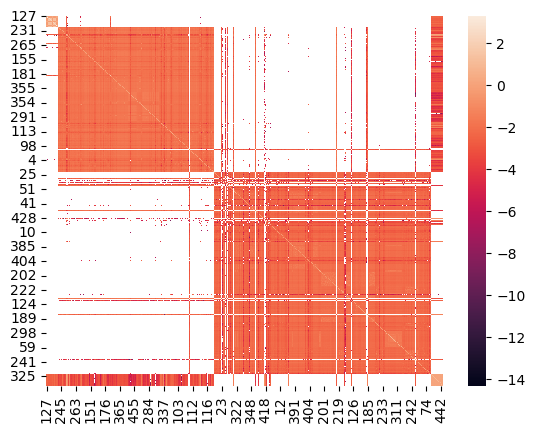

In [250]:
relAllOrder = relAll.loc[orderIndex, orderIndex]
relAllOrderLog = np.log(relAllOrder)
clustermap = sns.heatmap(relAllOrderLog)

plt.show()